In [256]:
#AAAAAAAAAAAAAAAAAAAAAAAAAAA

#    /\_/\          MIAOOOOOO
#   ( o.o )   <-- Il gatto della qualità del codice veglia su di te.
#    > ^ <

In [257]:
import numpy as np
import pandas as pd
from sklearn.metrics import matthews_corrcoef,f1_score, confusion_matrix, precision_score, recall_score, balanced_accuracy_score
import matplotlib.pyplot as plt
import argparse
from pathlib import Path
plt.rcParams["figure.figsize"] = (15,9)

## extraction of the dataframes:

In [258]:
#output of the model df
df=pd.read_csv('/home/um40/LB2_project_Group_1/Models/SVM/SVM_pred_vs_test.csv')
df

,UniprotID,true_class,pred_class
0,A0A0B5L781,0,0
1,A0A0D1CRC9,0,0
2,A0A0D1DWQ2,1,1
3,A0A0D1E3S6,0,0
4,A0A0F7YZQ7,1,1
...,...,...,...
1941,S0DHV6,0,0
1942,S8EZA7,0,0
1943,S8F527,0,0
1944,W2SDE2,0,0


In [259]:
#dataframe of the whole original set with informations
data=pd.read_csv('/home/um40/LB2_project_Group_1/Data_preparation/Cleaned_merged_dataset.tsv',sep='\t')
data

,class,ID,organism_name,kingdom,length,cleavage_pos,early_trans,fold
0,0,Q6YN16,Homo sapiens,Metazoa,418,0,False,4
1,0,Q9Y3I1,Homo sapiens,Metazoa,522,0,False,3
2,0,P30044,Homo sapiens,Metazoa,214,0,False,5
3,0,P07954,Homo sapiens,Metazoa,510,0,False,-1
4,0,P21549,Homo sapiens,Metazoa,392,0,False,-1
...,...,...,...,...,...,...,...,...
9723,1,Q7M3V1,Chelonus sp. nr. curvimaculatus,Metazoa,246,20,False,5
9724,1,Q8MMH5,Pimpla hypochondriaca,Metazoa,61,20,False,3
9725,1,I6RA76,Scolopendra mutilans,Metazoa,64,18,False,1
9726,1,P0DPU7,Scolopendra dehaani,Metazoa,78,25,False,-1


# performance extraction


In [260]:
# EVALUATION OF THE PERFORMANCE:

def performance_metrics(y_test,y_pred):
    '''This function is used to store the performance metrics of the model on the benchmark set'''
    mcc= matthews_corrcoef(y_test, y_pred)
    precision= precision_score(y_test, y_pred)
    recall= recall_score(y_test, y_pred)
    f1=f1_score(y_test, y_pred)
    cm=confusion_matrix(y_test, y_pred)
    bal_acc=balanced_accuracy_score(y_test, y_pred)

    return mcc, f1, cm, precision, recall, bal_acc

In [261]:
performance=performance_metrics(df['true_class'], df['pred_class'])
performance

(0.8943876693297782,
 0.9061784897025171,
 array([[1707,   18],
        [  23,  198]]),
 0.9166666666666666,
 0.8959276018099548,
 0.9427464096006295)

#### extraction of the ids
In the following cell we extracted the IDs of the elements of the confusion matrix, in order to be able to do the analysis. 

In [262]:
def labeling_function(df):
    TN=df.loc[(df['true_class']==0) & (df['pred_class']==0)]['UniprotID'].tolist()

    TP=df.loc[(df['true_class']==1) & (df['pred_class']==1)]['UniprotID'].tolist()

    FN=df.loc[(df['true_class']==1) & (df['pred_class']==0)]['UniprotID'].tolist()

    FP=df.loc[(df['true_class']==0) & (df['pred_class']==1)]['UniprotID'].tolist()

    return TN, TP, FN, FP

TN, TP, FN, FP = labeling_function(df)

In [263]:
tn_trans=data.loc[data['ID'].isin(TN) & data['early_trans']==True]['ID'].tolist()
print(len(tn_trans))
fp_trans=data.loc[data['ID'].isin(FP) & data['early_trans']==True]['ID'].tolist()

print(len(fp_trans))

tp_trans=data.loc[data['ID'].isin(TP) & data['early_trans']==True]['ID'].tolist()
print(len(tp_trans))
fn_trans=data.loc[data['ID'].isin(FN) & data['early_trans']==True]['ID'].tolist()
print(len(fn_trans))

## sono meno perche sono solo sul test set, mentre i primi sono sul dataset completo. 


94
12
0
0


Already from here the fact that no transmembran elix is present in the positive dataset  (TP+FN) is ok.

In [264]:
data['early_trans'].value_counts()

False    9186
True      542
Name: early_trans, dtype: int64

In [265]:
TN

['A0A0B5L781',
 'A0A0D1CRC9',
 'A0A0D1E3S6',
 'A0A0G2K309',
 'A0A120KVR8',
 'A0A1D8PRB7',
 'A0A1D9BZF0',
 'A0A2H1A5W4',
 'A0A2I0C2C6',
 'A0A509AFM3',
 'A0A509AQJ1',
 'A0A509ARF0',
 'A0A5E4M3Q4',
 'A0A7J6K629',
 'A0JNW5',
 'A1A6M1',
 'A1Z8F4',
 'A1Z9G3',
 'A2A9C3',
 'A2ADA5',
 'A2AG06',
 'A2AG58',
 'A2AIV2',
 'A2AMM0',
 'A2ARP9',
 'A2SWM2',
 'A3KPQ7',
 'A3R064',
 'A5A6S6',
 'A6H8H2',
 'A6NKF2',
 'A6NLJ0',
 'A8CVF3',
 'B4XT64',
 'B5TYT3',
 'B6HLT9',
 'B6HU70',
 'B6TTV8',
 'B7WN96',
 'B8BDQ4',
 'B8Y6I0',
 'B9EJG8',
 'B9F1C0',
 'B9TSP7',
 'C0HLN0',
 'C0HLU2',
 'C0HM83',
 'C0HM98',
 'C4LY96',
 'C4QWS8',
 'C4R5T1',
 'C8V329',
 'D0VWV4',
 'D3KY98',
 'D3YN49',
 'D3Z6Q9',
 'D3ZK93',
 'D3ZKT0',
 'E2RU10',
 'E7F568',
 'E9Q2Z1',
 'F1M386',
 'F4HQA1',
 'F4HXU3',
 'F4HYD7',
 'F4HYF3',
 'F4I718',
 'F4IF36',
 'F4IY62',
 'F4J284',
 'F4JCU0',
 'F4JV80',
 'F4JVI3',
 'F4K1B4',
 'F4K410',
 'F4K687',
 'F4KHG6',
 'F8VPN2',
 'F8VPU2',
 'G3UVW3',
 'G3XA57',
 'G4SLH0',
 'G5DGA8',
 'G5EC23',
 'G5ECN5',
 'G5ED47'

In [266]:
fpr_tm=len(fp_trans)/(len(fp_trans)+len(tn_trans))
fpr_tot=len(FP)/(len(TP)+len(TN))
print(f'fpr_tot: {fpr_tot}\nfpr_tm: {fpr_tm}')

fpr_tot: 0.009448818897637795
fpr_tm: 0.11320754716981132


The FPR of the transmembrane proteins is 10 times higher than the FPR of the total dataset. This was expected since the residues of protein with a transmembrane secondary structure at N terminal, is more prone to be confused by the model as the hydrophobic region of the signal peptide. 

## Distribution analysis:

In [267]:
#extracting the number of entries for each taxa in the test fold
taxa=data.loc[data["fold"] ==-1].groupby('kingdom').size()

In [268]:
print(taxa)

kingdom
Fungi       519
Metazoa    1063
Other        44
Plants      320
dtype: int64


In [269]:
FP_taxa=data.loc[data['ID'].isin(FP)]['kingdom'].value_counts()
FN_taxa=data.loc[data['ID'].isin(FN)]['kingdom'].value_counts()

In [270]:

def plot_taxa_distribution(FP,FN,data):
    FP_taxa=data.loc[data['ID'].isin(FP)]['kingdom'].value_counts()
    FN_taxa=data.loc[data['ID'].isin(FN)]['kingdom'].value_counts()

    taxa_df = pd.DataFrame({'False Positives': FP_taxa, 'False Negatives': FN_taxa})
    taxa_df_normalized = taxa_df.div(taxa_df.sum(axis=1), axis=0) * 100 

    ax= taxa_df.plot(kind='bar', color=['red', 'blue'], alpha=0.5)

    for p in ax.patches:
        h = p.get_height()
        if int(h)==0:
            pass
        else:
            ax.annotate(f'{int(h)}%',
                    (p.get_x() + p.get_width() / 2, h / 2),
                    ha='center', va='center')

    plt.title('Distribution of False Positives and False Negatives across Taxa', weight='bold')
    plt.xlabel('Taxa')
    plt.ylabel('percentage')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig('taxa_distribution.png', dpi=900)
    plt.show()

def plot_taxa_norm_distribution(FP,FN,data):
    FP_taxa=data.loc[data['ID'].isin(FP)]['kingdom'].value_counts()
    FN_taxa=data.loc[data['ID'].isin(FN)]['kingdom'].value_counts()

    print(FN_taxa)
    print(taxa)

    FP_taxa = FP_taxa / taxa.sum() * 100
    FN_taxa = FN_taxa / taxa.sum() * 100

    taxa_df = pd.DataFrame({'False Positives': FP_taxa, 'False Negatives': FN_taxa})
    #taxa_df_normalized = taxa_df.div(taxa_df.sum(axis=1), axis=0) * 100 
    taxa_df_normalized = taxa_df

    ax=taxa_df_normalized.plot(kind='bar', color=['red', 'blue'], alpha=0.5)

    for p in ax.patches:
            h = p.get_height()
            if int(h)==0:
                pass
            else:
                ax.annotate(f'{int(h)}%',
                        (p.get_x() + p.get_width() / 2, h / 2),
                        ha='center', va='center')


    plt.title('Distribution of False Positives and False Negatives across Taxa', weight='bold')
    plt.xlabel('Taxa')
    plt.ylabel('percentage')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig('taxa_distribution.png', dpi=900, bbox_inches='tight', facecolor='white', edgecolor='none')
    plt.show()



def Helix_presence(FP,data):
    FP_helix = data.loc[data['ID'].isin(FP) & (data['early_trans'] == True)]['early_trans'].value_counts()
    FP_No_helix = data.loc[data['ID'].isin(FP) & (data['early_trans'] == False)]['early_trans'].value_counts()

    counts = pd.DataFrame({'Helix Presence': FP_helix, 'No Helix Presence': FP_No_helix})

    ax= counts.plot(kind='bar', color=['red', 'orange'], alpha=0.5)
    for p in ax.patches:
                h = p.get_height()
                if int(h)==0:
                    pass
                else:
                    ax.annotate(f'{int(h)}%',
                            (p.get_x() + p.get_width() / 2, h / 2),
                            ha='center', va='center')

    plt.title('Distribution of False Positives across Helix Presence', weight='bold')
    plt.xlabel('Helix Presence')
    plt.ylabel('Count')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig('helix_distribution.png', dpi=900)
    plt.show()



def Helix_presence_norm(FP,data):
    FP_helix = data.loc[data['ID'].isin(FP) & (data['early_trans'] == True)]['early_trans'].value_counts()
    FP_No_helix = data.loc[data['ID'].isin(FP) & (data['early_trans'] == False)]['early_trans'].value_counts()

    Number_helix = data.loc[data['early_trans'] == True]['early_trans'].value_counts()
    Number_No_helix = data.loc[data['early_trans'] == False]['early_trans'].value_counts()

    FP_helix = FP_helix / Number_helix * 100
    FP_No_helix = FP_No_helix / Number_No_helix * 100

    counts = pd.DataFrame({'Helix Presence': FP_helix, 'No Helix Presence': FP_No_helix})

    ax= counts.plot(kind='bar', color=['red', 'orange'], alpha=0.5)
    for p in ax.patches:
        h = p.get_height()
        if h != 0:
            ax.annotate(
                f'{float(h):.2f}%',
                (p.get_x() + p.get_width() / 2, h),
                ha='center',
                va='bottom',
                xytext=(0, 3),
                textcoords='offset points'
            )

    plt.title('Distribution of False Positives across Helix Presence', weight='bold')
    plt.xlabel('Helix Presence')
    plt.ylabel('percentage')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig('helix_distribution_norm.png', dpi=900)
    plt.show()


### TAXA:
We can observe that the distribution of the false positive and negatives in all the taxas are pretty much similar, changing at most of 2%. Here the values though are mainly due for the number of entries of each taxa in the entire fold set, it is not informative for how precise is the model in characterising the singular taxa. 


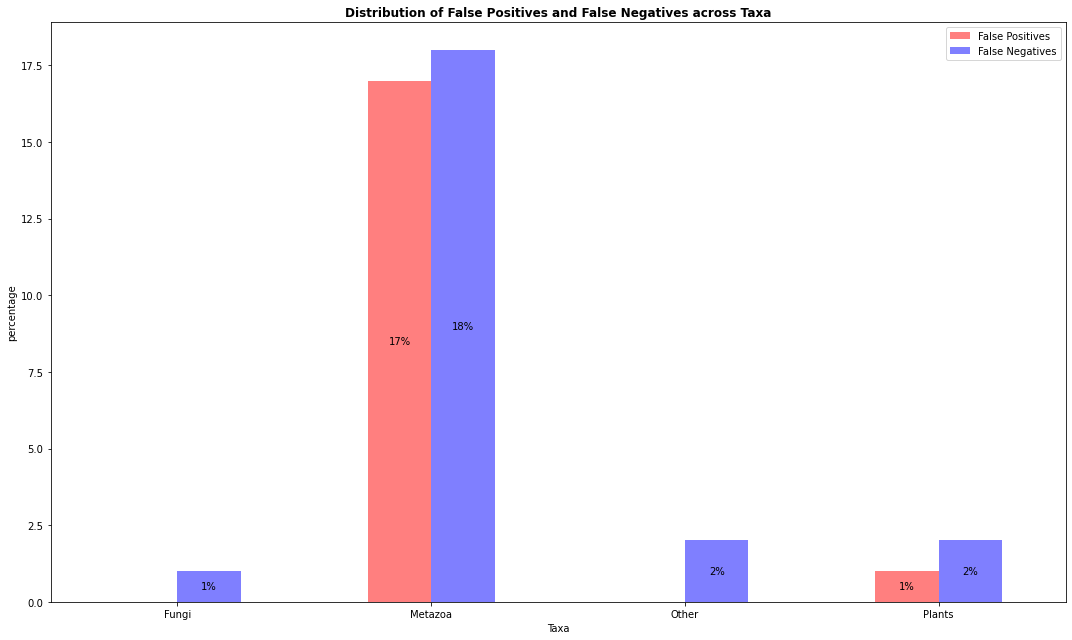

In [271]:
plot_taxa_distribution(FP,FN,data)


Metazoa    18
Other       2
Plants      2
Fungi       1
Name: kingdom, dtype: int64
kingdom
Fungi       519
Metazoa    1063
Other        44
Plants      320
dtype: int64


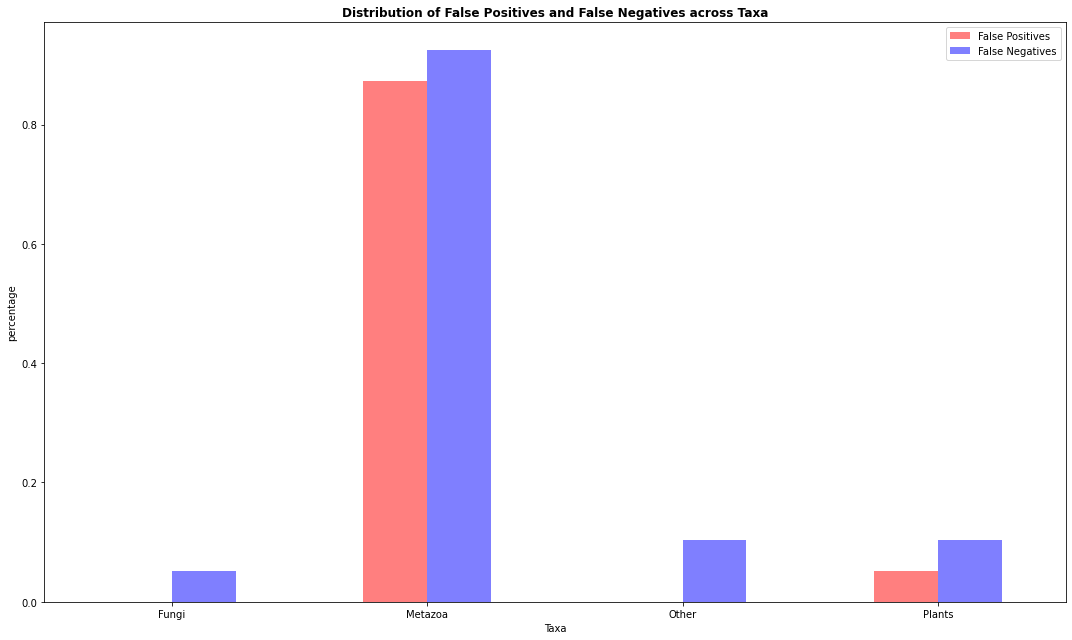

In [272]:
plot_taxa_norm_distribution(FP,FN,data)

In [273]:
def plot_taxa_all_distribution(FP,FN, TP, TN, data):
    Correctly_predicted = data.loc[data['ID'].isin(TP or TN)]['kingdom'].value_counts()
    FP_taxa=data.loc[data['ID'].isin(FP)]['kingdom'].value_counts()
    FN_taxa=data.loc[data['ID'].isin(FN)]['kingdom'].value_counts()

    

    taxa_df = pd.DataFrame({'False Positives': FP_taxa, 'False Negatives': FN_taxa, 'Correctly Predicted': Correctly_predicted})

    taxa_df_normalized = taxa_df.div(taxa_df.sum(axis=1), axis=0) * 100

    ax= taxa_df_normalized.plot(kind='bar', color=['red', 'blue', 'green'], alpha=0.5)

    for p in ax.patches:
        h = p.get_height()
        if int(h)==0:
            pass
        else:
            ax.annotate(f'{int(h)}%',
                    (p.get_x() + p.get_width() / 2, h / 2),
                    ha='center', va='center')


 
    plt.title('Distribution of False Positives and False Negatives across Kingdoms', weight='bold')
    plt.xlabel('Kingdoms')
    plt.ylabel('percentage')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.figure(figsize=(20, 12))
    plt.savefig('kingdom_distribution_norm.png', dpi=900)
    plt.show()

   

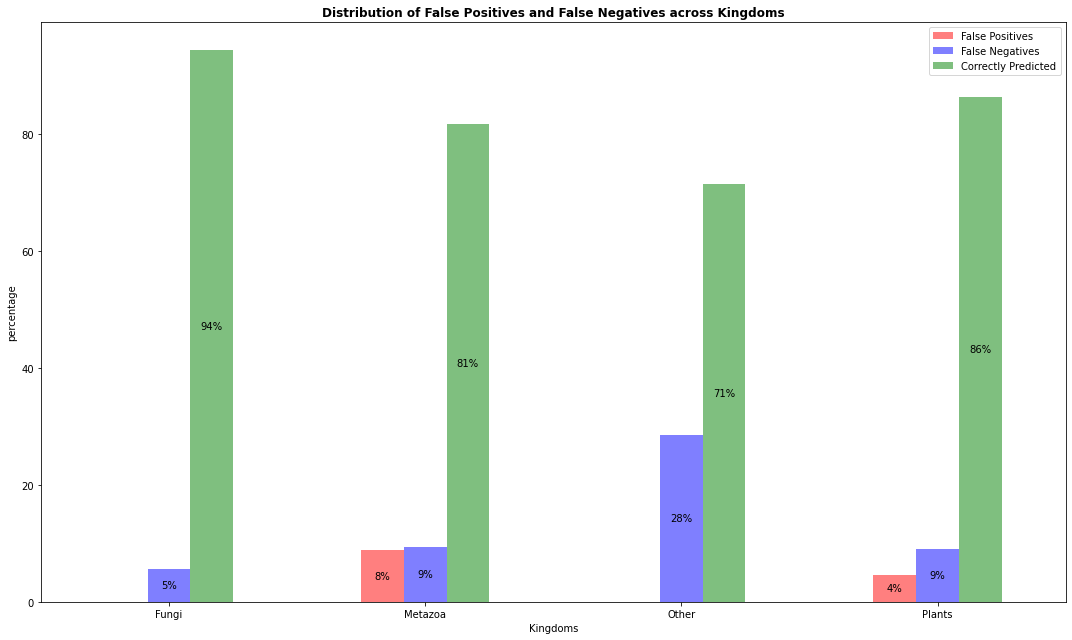

<Figure size 1440x864 with 0 Axes>

In [274]:
plot_taxa_all_distribution(FP,FN, TP, TN, data)

This plot is normalized for each taxa on the number of entries inside of them. It informs us on the accuracy of the model for each taxa singularly, showing us that the model has overall a similar performance for each of them. There is an unbalance on the number of FP , which are present in all the classes, on the contrary FN are totally absent in fungi and other. We have not enought samples of FP and FN to actually reason them with a class unbalance. 

In [ ]:
def plot_species_all_distribution(FP,FN, TP, TN, data):

    plt.rcParams["figure.figsize"] = (15,9)


    n = 4
    top = data['organism_name'].value_counts().head(n).index

    # In "df[~df", the tilde operator means NOT!, and so is used in this scenario to filter out the top n organisms from the dataframe.  
    data.loc[~data['organism_name'].isin(top), 'organism_name'] = 'Other'
    data['organism_name'] = data['organism_name'].replace('Saccharomyces cerevisiae (strain ATCC 204508 / S288c)', 
        'Saccharomyces cerevisiae'
    )
    data['organism_name'] = data['organism_name'].replace('Schizosaccharomyces pombe (strain 972 / ATCC 24843)', 
        'S. pombe'
    )

    Correctly_predicted = data.loc[data['ID'].isin(TP or TN)]['organism_name'].value_counts()
    FP_taxa=data.loc[data['ID'].isin(FP)]['organism_name'].value_counts()
    FN_taxa=data.loc[data['ID'].isin(FN)]['organism_name'].value_counts()

    print(FN_taxa)
    print(FP_taxa)
    print(Correctly_predicted)


    

    taxa_df = pd.DataFrame({'False Positives': FP_taxa, 'False Negatives': FN_taxa, 'Correctly Predicted': Correctly_predicted})

    taxa_df_normalized = taxa_df.div(taxa_df.sum(axis=1), axis=0) * 100

    ax= taxa_df_normalized.plot(kind='bar', color=['red', 'blue', 'green'], alpha=0.5)

    for p in ax.patches:
        h = p.get_height()
        if int(h)==0:
            pass
        else:
            ax.annotate(f'{int(h)}%',
                    (p.get_x() + p.get_width() / 2, h / 2),
                    ha='center', va='center')


 
    plt.title('Distribution of False Positives and False Negatives across Species', weight='bold')
    plt.xlabel('Species')
    plt.ylabel('percentage')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('taxa_distribution.png', dpi=900, bbox_inches='tight', facecolor='white', edgecolor='none')
    plt.show()


Other           18
Homo sapiens     4
Mus musculus     1
Name: organism_name, dtype: int64
Homo sapiens               8
Mus musculus               6
Other                      2
Arabidopsis thaliana       1
Drosophila melanogaster    1
Name: organism_name, dtype: int64
Other                       120
Homo sapiens                 57
Mus musculus                 14
Saccharomyces cerevisiae      3
Arabidopsis thaliana          2
Drosophila melanogaster       2
Name: organism_name, dtype: int64


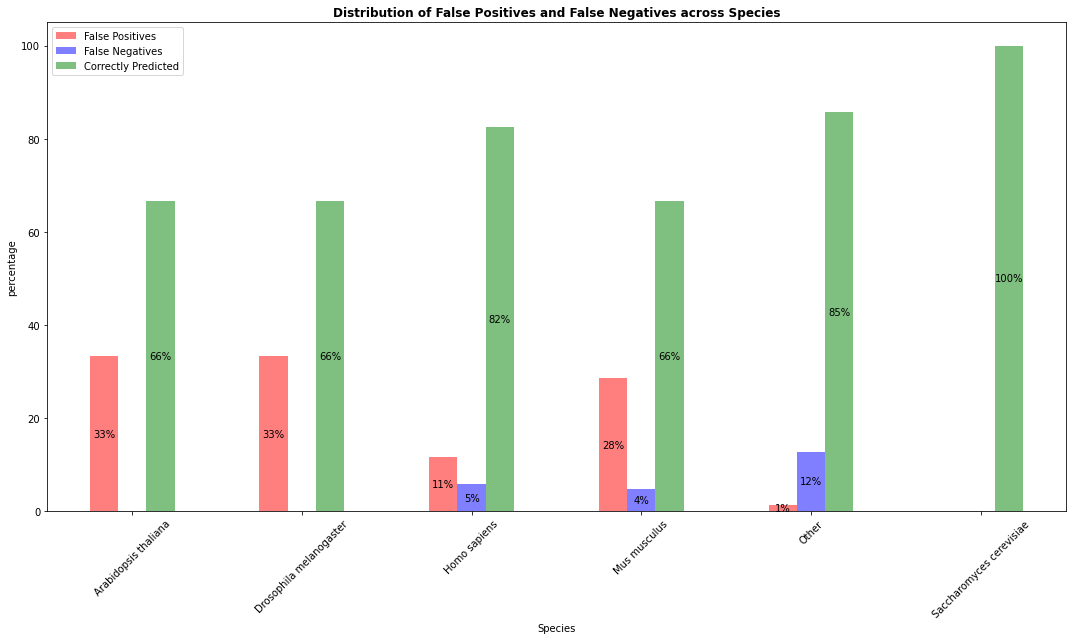

In [276]:
plot_species_all_distribution(FP,FN, TP, TN, data)

The species distribution shows as well a similar performance. The number of samples of Saccharomyces Cerevisiae and Arabidopsis Thaliana is too small to actually have any conclusion (3 and 2 samples respectively in the test set). On the other hand the number of false positives in homo sapiens and mus musculus is higher than in Other. The unbalance of the distribution might be due to some evolutive characteristic since both homo sapiens and mus musculus are mammals. 

### HELIX:

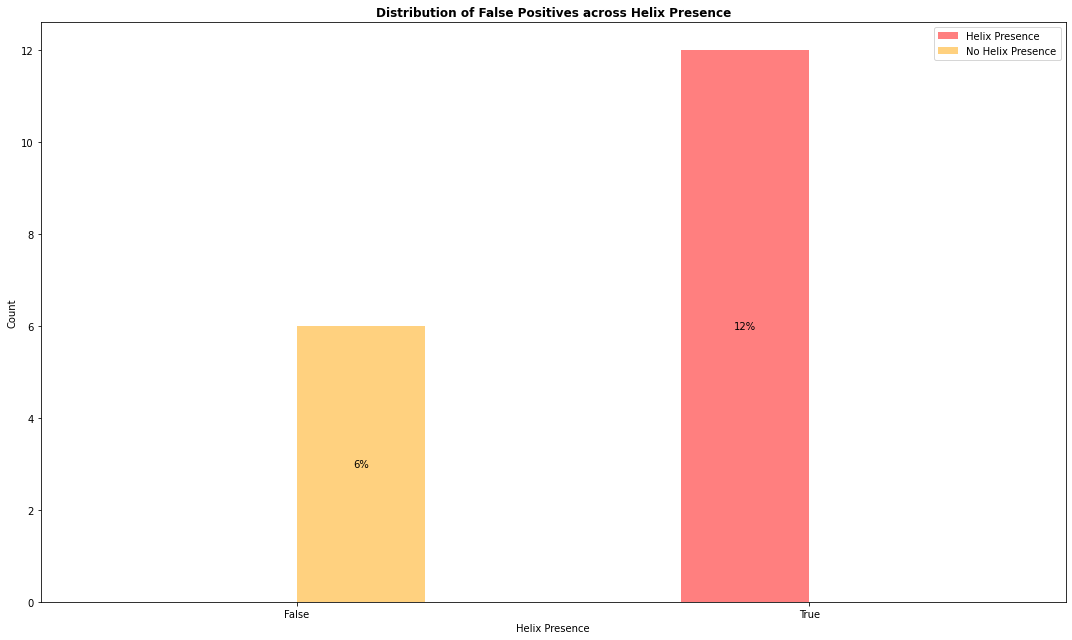

In [277]:
Helix_presence(FP,data)

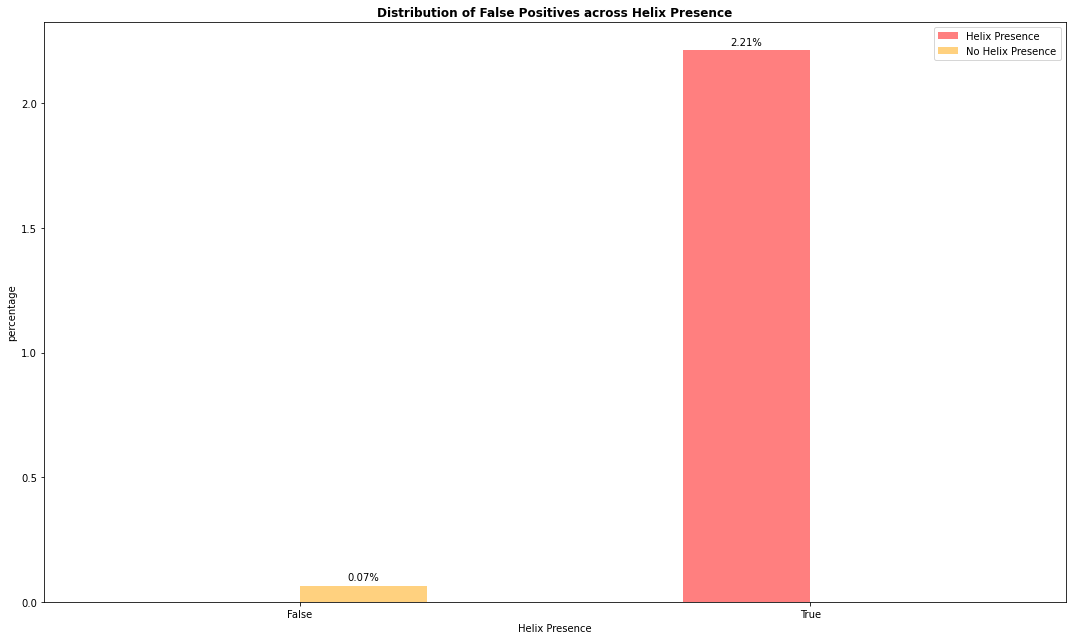

In [278]:
Helix_presence_norm(FP,data)

In this histogram we can observe that the percentage of false positive is doubled in the proteins containing a transmembrane helix.